# Brustkrebs erkennen mit maschinellem Lernen

**Grundlagen von Machine Learning und Sprachmodellen** · Modul Gesundheitssystemwissenschaften (JMM)

In diesem Notebook trainieren Sie selbst ein Modell, das aus Messungen an Zellkernen vorhersagt, ob ein Knoten in der Brust **gutartig** oder **bösartig** ist.

### So funktioniert es
* Das Notebook besteht aus **Textzellen** (wie dieser) und **Rechenzellen**. Den Programmcode der Rechenzellen haben wir eingeklappt: Sie müssen ihn nicht lesen.
* Klicken Sie in eine Rechenzelle und drücken Sie **Shift + Enter** (oder ▶ oben in der Symbolleiste). Das Ergebnis erscheint darunter.
* Gehen Sie **von oben nach unten** vor. Jede Zelle braucht die vorherigen.
* Wo **Schieberegler** oder **Auswahlfelder** erscheinen: ausprobieren!
* Falls etwas hängt: Menü *Kernel* → *Restart Kernel and Run All Cells* (bzw. *Neu starten und alle Zellen ausführen*).

Neugierig auf den Code? Klicken Sie auf die drei Punkte bzw. den kleinen Balken links neben einer Zelle, um ihn aufzuklappen.

---
## Schritt 0: Vorbereitung
Führen Sie diese Zelle aus. Beim ersten Mal dauert das **bis zu einer Minute**, weil Python im Browser geladen wird. Warten Sie, bis „Bereit!“ erscheint.

In [2]:
%pip install -q ipywidgets
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display, Markdown
from scipy.stats import beta
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve, roc_auc_score

plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
BLAU, ROT, GRUEN, ORANGE, GRAU = "#2E86C1", "#C0392B", "#229954", "#F39C12", "#7F8C8D"

roh = load_breast_cancer()
NAMEN = {
    "mean radius": "Grösse der Zellkerne (Radius)",
    "mean texture": "Textur (Schwankung der Grauwerte)",
    "mean perimeter": "Umfang der Zellkerne",
    "mean area": "Fläche der Zellkerne",
    "mean smoothness": "Glattheit der Kontur",
    "mean compactness": "Kompaktheit",
    "mean concavity": "Tiefe der Einbuchtungen",
    "mean concave points": "Anzahl Einbuchtungen",
    "mean symmetry": "Symmetrie",
    "mean fractal dimension": "Rauheit der Kontur",
}
alle_merkmale = pd.DataFrame(roh.data, columns=roh.feature_names)        # alle 30 Merkmale
merkmale = alle_merkmale[list(NAMEN)].rename(columns=NAMEN)               # die 10 Mittelwerte, deutsch
y = (roh.target == 0).astype(int)                                         # 1 = bösartig, 0 = gutartig
diagnose = np.where(y == 1, "bösartig", "gutartig")

# Aufteilung in Trainings- und Testdaten (70 % / 30 %), immer gleich
i_train, i_test = train_test_split(np.arange(len(y)), test_size=0.3, random_state=1, stratify=y)

def fehler_prozent(modell, X, y_wahr):
    return 100 * (1 - modell.score(X, y_wahr))

def kennzahlen(y_wahr, risiko, schwelle):
    pos = risiko >= schwelle
    rp = int(np.sum(pos & (y_wahr == 1))); fp = int(np.sum(pos & (y_wahr == 0)))
    fn = int(np.sum(~pos & (y_wahr == 1))); rn = int(np.sum(~pos & (y_wahr == 0)))
    return rp, fp, fn, rn

def konfidenzintervall(k, n):
    """95 %-Konfidenzintervall (Clopper-Pearson) für einen Anteil k/n."""
    if n == 0:
        return (np.nan, np.nan)
    unten = beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0
    oben = beta.ppf(0.975, k + 1, n - k) if k < n else 1.0
    return unten, oben

print(f"Bereit! Datensatz mit {len(y)} Patientinnen geladen "
      f"({(y == 0).sum()} gutartig, {(y == 1).sum()} bösartig).")

Note: you may need to restart the kernel to use updated packages.
Bereit! Datensatz mit 569 Patientinnen geladen (357 gutartig, 212 bösartig).


---
## Schritt 1: Die Daten ansehen
Die Daten stammen aus dem *Breast Cancer Wisconsin (Diagnostic)* Datensatz. Bei 569 Patientinnen wurde ein Knoten in der Brust punktiert (Feinnadelpunktat). Im Mikroskopbild wurden die Zellkerne vermessen: Grösse, Form, Textur usw. Die Diagnose (gutartig oder bösartig) wurde später histologisch gesichert. Das ist unser **Label**.

Führen Sie die Zelle aus. Sie sehen die ersten Patientinnen als Tabelle und darunter die Verteilung eines Merkmals.

**Aufgabe:** Wählen Sie verschiedene Merkmale aus. *Welches Merkmal trennt gutartige und bösartige Befunde am besten? Welches kaum?*

In [3]:
tabelle = merkmale.iloc[:, :4].round(2).copy()
tabelle["Diagnose (Label)"] = diagnose
display(tabelle.head(6))

def zeige_merkmal(merkmal):
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    werte = merkmale[merkmal]
    bins = np.linspace(werte.min(), werte.max(), 30)
    ax.hist(werte[y == 0], bins=bins, alpha=0.6, color=BLAU, label="gutartig")
    ax.hist(werte[y == 1], bins=bins, alpha=0.6, color=ROT, label="bösartig")
    ax.set_xlabel(merkmal); ax.set_ylabel("Anzahl Patientinnen"); ax.legend()
    plt.show()

interact(zeige_merkmal, merkmal=widgets.Dropdown(options=list(merkmale.columns), description="Merkmal:",
                                                 style={"description_width": "initial"}));

,Grösse der Zellkerne (Radius),Textur (Schwankung der Grauwerte),Umfang der Zellkerne,Fläche der Zellkerne,Diagnose (Label)
0,17.99,10.38,122.80,1001.0,bösartig
1,20.57,17.77,132.90,1326.0,bösartig
2,19.69,21.25,130.00,1203.0,bösartig
3,11.42,20.38,77.58,386.1,bösartig
4,20.29,14.34,135.10,1297.0,bösartig
5,12.45,15.70,82.57,477.1,bösartig


interactive(children=(Dropdown(description='Merkmal:', options=('Grösse der Zellkerne (Radius)', 'Textur (Schw…

---
## Schritt 2: Trainings- und Testdaten trennen
Bevor wir ein Modell trainieren, legen wir **30 % der Patientinnen zur Seite**. Diese **Testdaten** schaut das Modell beim Lernen nie an. Nur so können wir später ehrlich prüfen, wie gut es bei *neuen* Patientinnen ist.

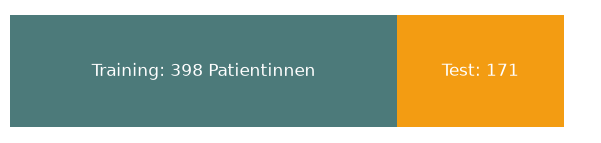

Trainingsdaten: 148 bösartig, 250 gutartig
Testdaten:      64 bösartig, 107 gutartig


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 1.6))
n_tr, n_te = len(i_train), len(i_test)
ax.barh(0, n_tr, color="#4C7A7A"); ax.barh(0, n_te, left=n_tr, color=ORANGE)
ax.text(n_tr / 2, 0, f"Training: {n_tr} Patientinnen", ha="center", va="center", color="white", fontsize=12)
ax.text(n_tr + n_te / 2, 0, f"Test: {n_te}", ha="center", va="center", color="white", fontsize=12)
ax.axis("off"); plt.show()
print(f"Trainingsdaten: {y[i_train].sum()} bösartig, {(y[i_train] == 0).sum()} gutartig")
print(f"Testdaten:      {y[i_test].sum()} bösartig, {(y[i_test] == 0).sum()} gutartig")

---
## Schritt 3: Ein Modell trainieren
Jetzt lernt eine **logistische Regression** aus den Trainingsdaten eine **Entscheidungsgrenze**: Auf der roten Seite sagt das Modell „bösartig“, auf der blauen „gutartig“. Die Farbintensität zeigt, wie sicher das Modell ist.

**Aufgaben:**
1. Wie gross ist der Fehler auf den **Trainingsdaten**, wie gross auf den **Testdaten**?
2. Probieren Sie andere Merkmalspaare aus. Mit welchen zwei Merkmalen wird das Modell am besten?

In [ ]:
def trainiere_zwei_merkmale(merkmal_x, merkmal_y, testdaten_zeigen):
    X = merkmale[[merkmal_x, merkmal_y]].values
    modell = make_pipeline(StandardScaler(), LogisticRegression())
    modell.fit(X[i_train], y[i_train])
    fig, ax = plt.subplots(figsize=(7.5, 5))
    rx = np.linspace(X[:, 0].min(), X[:, 0].max(), 200); ry = np.linspace(X[:, 1].min(), X[:, 1].max(), 200)
    gx, gy = np.meshgrid(rx, ry)
    p = modell.predict_proba(np.c_[gx.ravel(), gy.ravel()])[:, 1].reshape(gx.shape)
    ax.contourf(gx, gy, p, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.35)
    ax.contour(gx, gy, p, levels=[0.5], colors="black", linestyles="--")
    tr = i_train
    ax.scatter(X[tr][y[tr] == 0, 0], X[tr][y[tr] == 0, 1], c=BLAU, s=18, label="Training: gutartig")
    ax.scatter(X[tr][y[tr] == 1, 0], X[tr][y[tr] == 1, 1], c=ROT, s=18, marker="s", label="Training: bösartig")
    if testdaten_zeigen:
        te = i_test
        ax.scatter(X[te][y[te] == 0, 0], X[te][y[te] == 0, 1], facecolors="none", edgecolors=BLAU, s=60, marker="^", label="Test: gutartig")
        ax.scatter(X[te][y[te] == 1, 0], X[te][y[te] == 1, 1], facecolors="none", edgecolors=ROT, s=60, marker="^", label="Test: bösartig")
    ax.set_xlabel(merkmal_x); ax.set_ylabel(merkmal_y); ax.legend(fontsize=8, loc="best")
    plt.show()
    print(f"Fehler auf den Trainingsdaten: {fehler_prozent(modell, X[i_train], y[i_train]):.1f} % falsch klassifiziert")
    print(f"Fehler auf den Testdaten:      {fehler_prozent(modell, X[i_test], y[i_test]):.1f} % falsch klassifiziert")

namen = list(merkmale.columns)
stil = {"description_width": "initial"}
interact(trainiere_zwei_merkmale,
         merkmal_x=widgets.Dropdown(options=namen, value=namen[0], description="Merkmal x-Achse:", style=stil),
         merkmal_y=widgets.Dropdown(options=namen, value=namen[1], description="Merkmal y-Achse:", style=stil),
         testdaten_zeigen=widgets.Checkbox(value=False, description="Testdaten zeigen"));

interactive(children=(Dropdown(description='Merkmal x-Achse:', options=('Grösse der Zellkerne (Radius)', 'Text…

---
## Schritt 4: Modellkomplexität und Overfitting
Bisher war die Entscheidungsgrenze eine **Gerade**. Mit dem Schieberegler **Komplexität** darf die Grenze immer kurviger werden. Damit wir den Effekt gut sehen, nehmen wir zwei eher schwache Merkmale (**Textur** und **Glattheit der Kontur**) und trainieren nur mit **wenigen** Patientinnen.

**Aufgabe:** Erhöhen Sie die Komplexität schrittweise. *Was passiert mit dem Fehler auf den Trainingsdaten? Und auf den Testdaten? Ab wann wird das Modell bei neuen Patientinnen schlechter?*

**Mini-Programmieren (freiwillig):** Die nächste Zelle enthält eine einzige Zeile Code. Ändern Sie die Zahl, z.B. auf `30` oder auf `398` (alle Trainingsdaten), führen Sie die Zelle aus und danach die Zelle darunter nochmals. *Wie verändert die Menge an Trainingsdaten das Overfitting?*

In [6]:
anzahl_trainingspatientinnen = 80

In [7]:
n = int(min(max(anzahl_trainingspatientinnen, 10), len(i_train)))
MX, MY = namen[1], namen[4]
X2 = merkmale[[MX, MY]].values
teil = np.random.default_rng(0).permutation(i_train)[:n]
grade = list(range(1, 9))
modelle, f_train, f_test = {}, [], []
for g in grade:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(g), StandardScaler(), LogisticRegression(C=1e6, max_iter=20000))
    m.fit(X2[teil], y[teil]); modelle[g] = m
    f_train.append(fehler_prozent(m, X2[teil], y[teil])); f_test.append(fehler_prozent(m, X2[i_test], y[i_test]))

def zeige_komplexitaet(komplexitaet):
    m = modelle[komplexitaet]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
    rx = np.linspace(X2[:, 0].min(), X2[:, 0].max(), 250); ry = np.linspace(X2[:, 1].min(), X2[:, 1].max(), 250)
    gx, gy = np.meshgrid(rx, ry)
    p = m.predict_proba(np.c_[gx.ravel(), gy.ravel()])[:, 1].reshape(gx.shape)
    a1.contourf(gx, gy, p, levels=[0, 0.5, 1], colors=[BLAU, ROT], alpha=0.18)
    a1.contour(gx, gy, p, levels=[0.5], colors="black", linewidths=1.5)
    te = i_test
    a1.scatter(X2[te][y[te] == 0, 0], X2[te][y[te] == 0, 1], c=BLAU, s=14, alpha=0.25, marker="^")
    a1.scatter(X2[te][y[te] == 1, 0], X2[te][y[te] == 1, 1], c=ROT, s=14, alpha=0.25, marker="^")
    a1.scatter(X2[teil][y[teil] == 0, 0], X2[teil][y[teil] == 0, 1], c=BLAU, s=30, edgecolors="black", label="Training: gutartig")
    a1.scatter(X2[teil][y[teil] == 1, 0], X2[teil][y[teil] == 1, 1], c=ROT, s=30, marker="s", edgecolors="black", label="Training: bösartig")
    a1.set_xlabel(MX); a1.set_ylabel(MY); a1.legend(fontsize=8, loc="upper right")
    a1.set_title(f"Komplexität {komplexitaet} (blasse Dreiecke = Testdaten)", fontsize=10)
    a2.plot(grade, f_train, "o-", color="#4C7A7A", label="Trainingsdaten")
    a2.plot(grade, f_test, "^-", color=ORANGE, label="Testdaten (neue Patientinnen)")
    a2.axvline(komplexitaet, color="black", ls=":")
    a2.set_xlabel("Komplexität des Modells"); a2.set_ylabel("Fehler (% falsch klassifiziert)")
    a2.set_ylim(0, max(max(f_test), max(f_train)) + 5); a2.legend(fontsize=9)
    plt.tight_layout(); plt.show()
    print(f"Komplexität {komplexitaet}: Trainingsfehler {f_train[komplexitaet-1]:.1f} %, Testfehler {f_test[komplexitaet-1]:.1f} %  (trainiert mit {n} Patientinnen)")

interact(zeige_komplexitaet, komplexitaet=widgets.IntSlider(min=1, max=8, value=1, description="Komplexität:",
                                                           continuous_update=False, style={"description_width": "initial"}));

interactive(children=(IntSlider(value=1, continuous_update=False, description='Komplexität:', max=8, min=1, st…

---
## Teil B · Schritt 5: Der Schwellenwert
Das Modell gibt für jede Patientin eine **Wahrscheinlichkeit** für „bösartig“ aus. Ab welcher Wahrscheinlichkeit wir „positiv“ sagen, ist der **Schwellenwert**. Hier sehen Sie die Ergebnisse auf den **Testdaten**.

**Aufgaben:**
1. Verschieben Sie den Schwellenwert. *Wie verändern sich Sensitivität, Spezifität und PPV?*
2. Angenommen, bei „positiv“ folgt eine **weitere Abklärung bzw. Operation**, bei „negativ“ nur eine **Verlaufskontrolle**. *Welche Schwelle würden Sie wählen? Was kostet ein falsch negativer, was ein falsch positiver Befund?*
3. Wählen Sie bei *Einsatzort* „Screening“. *Was passiert mit dem PPV, obwohl Sensitivität und Spezifität gleich bleiben?*

In [8]:
X_alle = alle_merkmale.values
MODELLE = {
    "einfach: 2 Merkmale (Grösse, Textur)": [0, 1],
    "voll: alle 30 Merkmale": list(range(30)),
}
risiko_test = {}
for name, spalten in MODELLE.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    m.fit(X_alle[i_train][:, spalten], y[i_train])
    risiko_test[name] = m.predict_proba(X_alle[i_test][:, spalten])[:, 1]
y_test = y[i_test]
praev_test = y_test.mean()
EINSATZORTE = {f"wie im Testdatensatz ({100*praev_test:.0f} %)": praev_test,
               "Abklärung in der Brustsprechstunde (10 %)": 0.10,
               "Screening (1 %)": 0.01}

def zeige_schwelle(modell, schwelle, einsatzort):
    r = risiko_test[modell]
    rp, fp, fn, rn = kennzahlen(y_test, r, schwelle)
    sens = rp / (rp + fn); spez = rn / (rn + fp)
    ppv_test = rp / (rp + fp) if rp + fp > 0 else float("nan")
    pr = EINSATZORTE[einsatzort]
    ppv_ort = sens * pr / (sens * pr + (1 - spez) * (1 - pr)) if sens * pr + (1 - spez) * (1 - pr) > 0 else float("nan")
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
    bins = np.linspace(0, 1, 21)
    a1.hist(r[y_test == 0], bins=bins, color=BLAU, alpha=0.6, label="gutartig")
    a1.hist(r[y_test == 1], bins=bins, color=ROT, alpha=0.6, label="bösartig")
    a1.axvline(schwelle, color="black", ls="--", lw=2); a1.set_xlabel("Vorhergesagte Wahrscheinlichkeit für bösartig")
    a1.set_ylabel("Anzahl Testpatientinnen"); a1.legend(fontsize=9); a1.set_title("Rechts der Linie: positiv", fontsize=10)
    werte = np.array([[rp, fp], [fn, rn]]); farben = np.array([[GRUEN, ORANGE], [ROT, GRUEN]])
    texte = np.array([["richtig positiv", "falsch positiv"], ["falsch negativ", "richtig negativ"]])
    for i in range(2):
        for j in range(2):
            a2.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=farben[i, j], alpha=0.3))
            a2.text(j + 0.5, 1.6 - i, str(werte[i, j]), ha="center", va="center", fontsize=18, weight="bold")
            a2.text(j + 0.5, 1.25 - i, texte[i, j], ha="center", va="center", fontsize=9)
    a2.set_xlim(0, 2); a2.set_ylim(0, 2); a2.set_xticks([0.5, 1.5]); a2.set_xticklabels(["bösartig", "gutartig"])
    a2.set_yticks([0.5, 1.5]); a2.set_yticklabels(["Modell:\nnegativ", "Modell:\npositiv"]); a2.set_title("Tatsächlich (Histologie)", fontsize=10)
    a2.tick_params(length=0)
    fpr, tpr, _ = roc_curve(y_test, r); auc = roc_auc_score(y_test, r)
    a3.plot(fpr, tpr, color="#4C7A7A", lw=2); a3.plot([0, 1], [0, 1], ls=":", color=GRAU)
    a3.plot(1 - spez, sens, "o", color="black", ms=10)
    a3.set_xlabel("1 − Spezifität"); a3.set_ylabel("Sensitivität"); a3.set_title(f"ROC-Kurve, AUC = {auc:.2f}", fontsize=10)
    a3.set_aspect("equal")
    plt.tight_layout(); plt.show()
    display(Markdown(
        f"**Sensitivität** {100*sens:.0f} % (von {rp+fn} bösartigen Befunden erkannt: {rp})  \n"
        f"**Spezifität** {100*spez:.0f} % (von {rn+fp} gutartigen Befunden richtig als gutartig erkannt: {rn})  \n"
        f"**PPV im Testdatensatz** {100*ppv_test:.0f} % (Anteil der positiven Befunde, die stimmen)  \n"
        f"**PPV am Einsatzort** „{einsatzort}“: **{100*ppv_ort:.0f} %**"))

interact(zeige_schwelle,
         modell=widgets.Dropdown(options=list(MODELLE), description="Modell:", style={"description_width": "initial"}),
         schwelle=widgets.FloatSlider(min=0.05, max=0.95, step=0.05, value=0.5, description="Schwellenwert:",
                                      continuous_update=False, style={"description_width": "initial"}),
         einsatzort=widgets.Dropdown(options=list(EINSATZORTE), description="Einsatzort (Prävalenz):",
                                     style={"description_width": "initial"}, layout=widgets.Layout(width="480px")));

interactive(children=(Dropdown(description='Modell:', options=('einfach: 2 Merkmale (Grösse, Textur)', 'voll: …

---
## Schritt 6: Kalibrierung
Wenn das Modell sagt „Risiko 30 %“, sollten von 100 solchen Patientinnen auch etwa 30 tatsächlich einen bösartigen Befund haben. Dafür teilen wir die Testpatientinnen nach vorhergesagtem Risiko in Gruppen ein und vergleichen mit dem tatsächlichen Anteil.

**Aufgabe:** *Liegen die Punkte nahe an der gestrichelten Diagonale (= perfekt kalibriert)?* Beachten Sie die Zahlen an den Punkten: In manchen Gruppen sind nur wenige Patientinnen. Dort ist die Schätzung unsicher.

In [9]:
def zeige_kalibrierung(modell):
    r = risiko_test[modell]
    grenzen = np.linspace(0, 1, 6)
    gruppe = np.clip(np.digitize(r, grenzen) - 1, 0, 4)
    fig, ax = plt.subplots(figsize=(5.2, 5))
    ax.plot([0, 1], [0, 1], ls="--", color=GRAU, label="perfekt kalibriert")
    for g in range(5):
        auswahl = gruppe == g
        if auswahl.sum() == 0:
            continue
        mx, my, nn = r[auswahl].mean(), y_test[auswahl].mean(), auswahl.sum()
        u, o = konfidenzintervall(int(y_test[auswahl].sum()), int(nn))
        ax.errorbar(mx, my, yerr=[[my - u], [o - my]], fmt="o", color=GRUEN, ms=8, capsize=4)
        ax.annotate(f"n={nn}", (mx, my), textcoords="offset points", xytext=(8, -12), fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Vorhergesagtes Risiko (Mittelwert der Gruppe)"); ax.set_ylabel("Tatsächlicher Anteil bösartig")
    ax.legend(loc="upper left"); plt.show()

interact(zeige_kalibrierung, modell=widgets.Dropdown(options=list(MODELLE), description="Modell:",
                                                     style={"description_width": "initial"}));

interactive(children=(Dropdown(description='Modell:', options=('einfach: 2 Merkmale (Grösse, Textur)', 'voll: …

---
## Schritt 7: Unsicherheit
Sensitivität und Spezifität sind **Schätzungen** aus einer Stichprobe. Je weniger Testpatientinnen, desto unsicherer. Die Balken zeigen das **95 %-Konfidenzintervall**.

**Aufgabe:** Verkleinern Sie den Testdatensatz. *Wie verändert sich das Intervall? Würden Sie einem Hersteller glauben, der eine Sensitivität von 95 % an 20 Patientinnen gemessen hat?*

In [ ]:
reihenfolge = np.random.default_rng(1).permutation(len(i_test))

def zeige_unsicherheit(anzahl_testpatientinnen):
    auswahl = reihenfolge[:anzahl_testpatientinnen]
    r = risiko_test["voll: alle 30 Merkmale"][auswahl]; yt = y_test[auswahl]
    rp, fp, fn, rn = kennzahlen(yt, r, 0.5)
    ergebnisse = [("Sensitivität", rp, rp + fn), ("Spezifität", rn, rn + fp)]
    fig, ax = plt.subplots(figsize=(7, 2.8))
    for i, (name, k, nn) in enumerate(ergebnisse):
        wert = k / nn if nn else np.nan; u, o = konfidenzintervall(k, nn)
        ax.errorbar(100 * wert, i, xerr=[[100 * (wert - u)], [100 * (o - wert)]], fmt="o", color="#4C7A7A", ms=9, capsize=6, lw=2)
        ax.text(101, i + 0.18, f"{100*wert:.0f} % (95 %-KI {100*u:.0f} bis {100*o:.0f} %), n = {nn}", fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels([e[0] for e in ergebnisse]); ax.set_ylim(-0.6, 1.6)
    ax.set_xlim(40, 140); ax.set_xticks(range(40, 101, 10)); ax.set_xlabel("%")
    ax.set_title(f"Modell mit allen 30 Merkmalen, Schwelle 0.5, {anzahl_testpatientinnen} Testpatientinnen", fontsize=10)
    plt.show()

interact(zeige_unsicherheit, anzahl_testpatientinnen=widgets.IntSlider(min=20, max=len(i_test), step=10, value=len(i_test),
                                                                       description="Anzahl Testpatientinnen:", continuous_update=False,
                                                                       style={"description_width": "initial"}, layout=widgets.Layout(width="480px")));

interactive(children=(IntSlider(value=171, continuous_update=False, description='Anzahl Testpatientinnen:', la…

---
## Bonus · Schritt 8: Ein anderes Spital (Verteilungsverschiebung)
Unser Modell wurde mit Daten aus *einem* Labor trainiert. Nun wird es in **Spital B** eingesetzt. Dort wird das Mikroskopbild anders aufgenommen, so dass alle Grössenmasse der Zellkerne (Radius, Umfang, Fläche) etwas **grösser** gemessen werden. Die Patientinnen sind dieselben wie im Testdatensatz, nur die Messung ist anders.

**Aufgabe:** Erhöhen Sie die Messabweichung. *Was passiert mit Sensitivität, Spezifität und dem durchschnittlich vorhergesagten Risiko? Würde das jemand im Spital B bemerken?*

In [ ]:
modell_voll = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_alle[i_train], y[i_train])
spalten_laenge = [i for i, n in enumerate(roh.feature_names) if ("radius" in n or "perimeter" in n)]
spalten_flaeche = [i for i, n in enumerate(roh.feature_names) if "area" in n]
basis = None

def zeige_spital_b(messabweichung_prozent):
    global basis
    f = 1 + messabweichung_prozent / 100
    Xb = X_alle[i_test].copy()
    Xb[:, spalten_laenge] *= f; Xb[:, spalten_flaeche] *= f ** 2
    r = modell_voll.predict_proba(Xb)[:, 1]
    rp, fp, fn, rn = kennzahlen(y_test, r, 0.5)
    werte = [100 * rp / (rp + fn), 100 * rn / (rn + fp), 100 * r.mean()]
    if basis is None:
        r0 = modell_voll.predict_proba(X_alle[i_test])[:, 1]; a, b, c, d = kennzahlen(y_test, r0, 0.5)
        basis = [100 * a / (a + c), 100 * d / (d + b), 100 * r0.mean()]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    x = np.arange(3); breite = 0.38
    ax.bar(x - breite / 2, basis, breite, color=GRAU, label="Spital A (wie im Training)")
    ax.bar(x + breite / 2, werte, breite, color=ORANGE, label=f"Spital B (Messabweichung +{messabweichung_prozent} %)")
    for xi, w in zip(x, werte):
        ax.text(xi + breite / 2, w + 1.5, f"{w:.0f}", ha="center", fontsize=10)
    ax.axhline(100 * y_test.mean(), color=ROT, ls=":", lw=1.5)
    ax.text(2.45, 100 * y_test.mean() + 2, "tatsächlicher Anteil\nbösartig", color=ROT, fontsize=8, ha="right")
    ax.set_xticks(x); ax.set_xticklabels(["Sensitivität (%)", "Spezifität (%)", "Ø vorhergesagtes Risiko (%)"])
    ax.set_ylim(0, 115); ax.legend(fontsize=9, loc="upper right"); plt.show()

interact(zeige_spital_b, messabweichung_prozent=widgets.IntSlider(min=0, max=40, step=5, value=0, description="Messabweichung in Spital B (%):",
                                                                  continuous_update=False, style={"description_width": "initial"},
                                                                  layout=widgets.Layout(width="520px")));

interactive(children=(IntSlider(value=0, continuous_update=False, description='Messabweichung in Spital B (%):…

---
## Was haben Sie gesehen?
* Ein Modell **lernt aus Beispielen** mit bekanntem Label. Die logistische Regression lernt dabei eine Entscheidungsgrenze.
* Auf den **Trainingsdaten** sieht ein Modell fast immer besser aus als auf **neuen Patientinnen**. Zu komplexe Modelle lernen die Trainingsdaten auswendig (**Overfitting**), besonders bei wenigen Daten.
* Der **Schwellenwert** verschiebt das Gleichgewicht zwischen Sensitivität und Spezifität. Welche Schwelle richtig ist, ist eine **klinische** Entscheidung.
* Der **PPV** hängt von der **Prävalenz am Einsatzort** ab.
* Gute Modelle sind **kalibriert**, und jede Kennzahl hat eine **Unsicherheit**.
* Ändern sich die Messungen am Einsatzort (**Verteilungsverschiebung**), kann ein gutes Modell unbemerkt schlecht werden.

*Datenquelle:* Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository. W.N. Street, W.H. Wolberg, O.L. Mangasarian (1993). Der Datensatz ist in scikit-learn enthalten.